In [7]:
%load_ext autoreload
%autoreload 2
    
from dask.distributed import Client
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.pyplot import cm
import cartopy.crs as ccrs

from cdrmip_extremes.extremes_pipeline import ExtremesPipeline
from cdrmip_extremes import (
    configs, load_pipeline, io_disk,  utils,
    extremes, plotting as pl, stats, gwl
)
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [9]:
expt = '1pctCO2-cdr'

In [10]:
base = PROC_DIR / 'CDRMIP' / 'extremes'
varname = 'tas'

ext_data = {
    name: io_disk.load_nested(base / name, f"{varname}_{name}", order=CDR_MODELS)
    for name in ['gwl_period_extremes', 'exceedances_median_multimodel', 'thresholds']
}

In [11]:
ext_mon_data = ext_data['gwl_period_extremes']
ext_freq = ext_data['exceedances_median_multimodel']
thresholds = ext_data['thresholds']

## Find mean temperature of hottest month either branch?

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_c

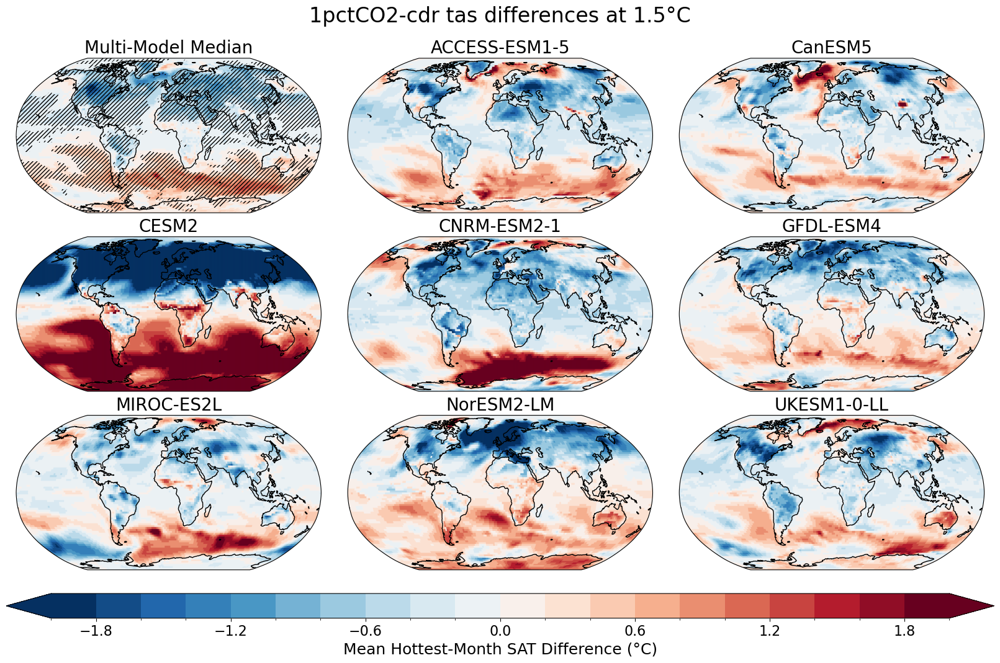

In [10]:
raw = extremes.ext_month_stat_diff(utils.reduce_member_tree(ext_mon_data), "heat", "mean")
diff = utils.reduce_models(raw)

fig, axes = pl.plot_gwl_diff(
    diff, expt=expt, varname="tas", gwl=1.5,
    levels=np.linspace(-2, 2, 21), cmap=cm.RdBu_r,
    agreement=stats.calc_agreement(raw, expt=expt),
    cbar_label="Mean Hottest-Month SAT Difference (°C)",
)

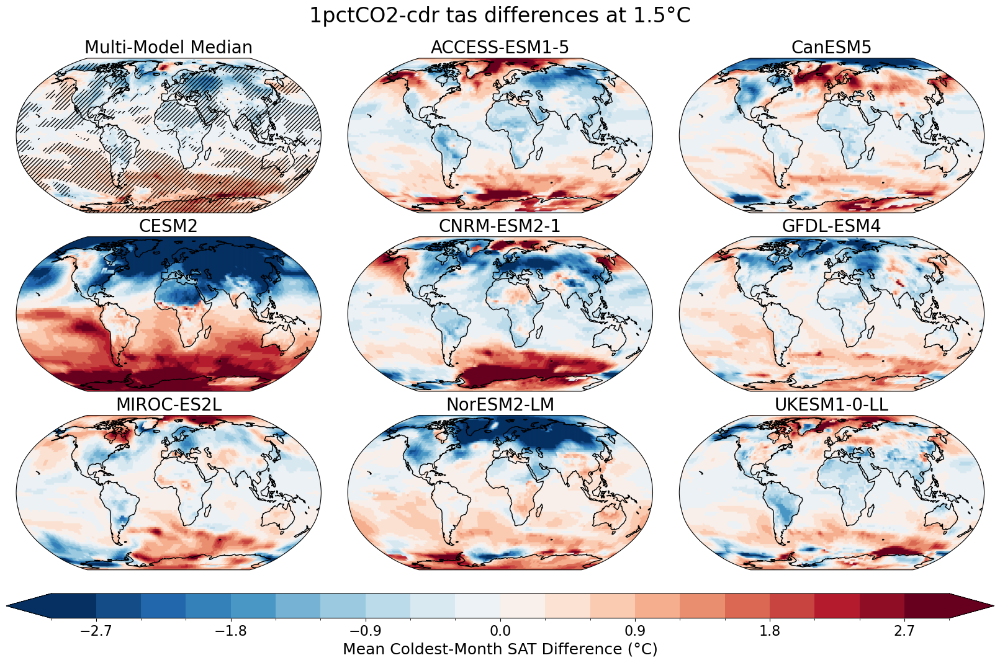

In [11]:
raw = extremes.ext_month_stat_diff(utils.reduce_member_tree(ext_mon_data), "cold", "mean")
diff = utils.reduce_models(raw)

fig, axes = pl.plot_gwl_diff(
    diff, expt=expt, varname="tas", gwl=1.5,
    levels=np.linspace(-3, 3, 21), cmap=cm.RdBu_r,
    agreement=stats.calc_agreement(raw, expt=expt),
    cbar_label="Mean Coldest-Month SAT Difference (°C)",
)

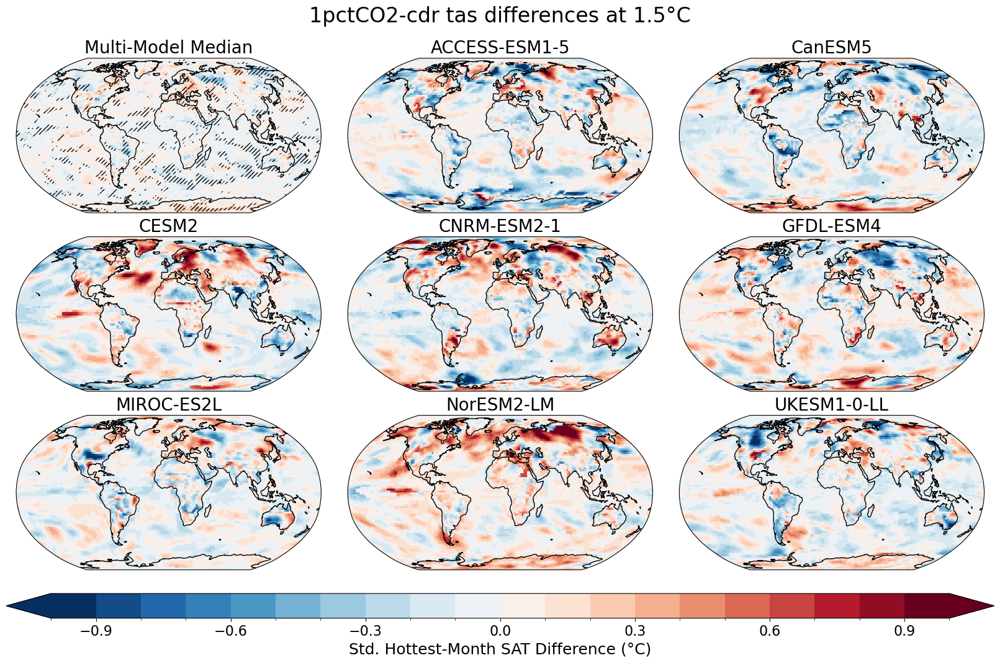

In [44]:
raw = extremes.ext_month_stat_diff(utils.reduce_member_tree(ext_mon_data), "heat", "std")
diff = utils.reduce_models(raw)

fig, axes = pl.plot_gwl_diff(
    diff, expt=expt, varname="tas", gwl=1.5,
    levels=np.linspace(-1, 1, 21), cmap=cm.RdBu_r,
    agreement=stats.calc_agreement(raw, expt=expt),
    cbar_label="Std. Hottest-Month SAT Difference (°C)",
)

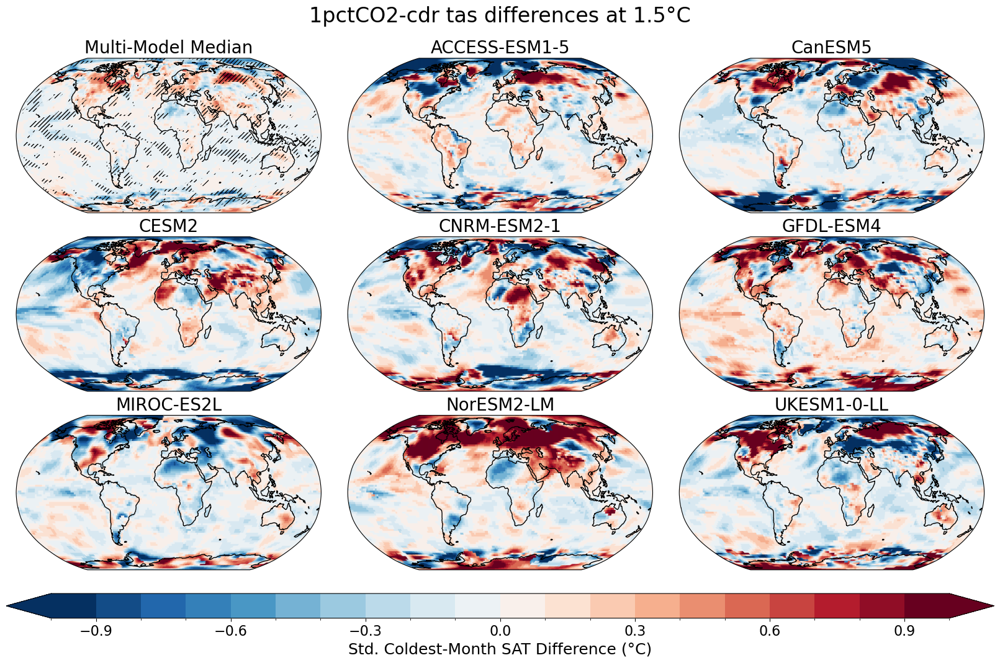

In [45]:
raw = extremes.ext_month_stat_diff(utils.reduce_member_tree(ext_mon_data), "cold", "std")
diff = utils.reduce_models(raw)

fig, axes = pl.plot_gwl_diff(
    diff, expt=expt, varname="tas", gwl=1.5,
    levels=np.linspace(-1, 1, 21), cmap=cm.RdBu_r,
    agreement=stats.calc_agreement(raw, expt=expt),
    cbar_label="Std. Coldest-Month SAT Difference (°C)",
)

## To what extent are changes in frequency driven by changes in the mean?

Can we take our pre-peak distributions and shift them artificially to determine the extent to which frequency changes are driven by changes in the mean or by changes in other characteristics of the distribution?

In [12]:
def counterfactual(ds, shift=True, scale=False, dim='year'):
    """
    Replace ramp_down with ramp_up anomalies, 
    moved to ramp_down's mean and/or rescaled to its std."""
    up, dn = ds.sel(branch='ramp_up'), ds.sel(branch='ramp_down')
    anom = up - up.mean(dim)
    if scale:
        anom = anom * dn.std(dim) / up.std(dim)
    base = dn.mean(dim) if shift else up.mean(dim)
    return xr.concat([up, (base + anom).assign_coords(branch='ramp_down')], dim='branch')

In [13]:
cases = {
    'shift': dict(shift=True),
    'scale': dict(shift=False, scale=True),
    'both': dict(shift=True, scale=True)
}

p = ExtremesPipeline(None, None)
p.thresholds = thresholds
for name, kw in cases.items():
    setattr(p, f'cf_{name}', utils.map_nested(lambda ds: counterfactual(ds['tas'], **kw), ext_mon_data))
    p.compute_exceedances(f'cf_{name}', save_as=f'exc_{name}')

In [14]:
def decompose(actual, cf, model, expt, ext_type='heat', thr='sigma1', gwl_val=1.5):
    # select one model/expt/ext_type/threshold/GWL map from a tree
    get = lambda tree: tree[model][expt][ext_type][thr].sel(gwl=gwl_val)
    # ramp_down - ramp_up frequency difference
    d = lambda x: x.sel(branch='ramp_down') - x.sel(branch='ramp_up')

    a = get(actual)
    s, sc, b = get(cf['shift']), get(cf['scale']), get(cf['both'])

    # Shift and scale contributions depend on the order they are applied in:
    #   shift first:  shift = d(s),         scale = d(b) - d(s)
    #   scale first:  shift = d(b) - d(sc), scale = d(sc)
    # so each is averaged over the two orderings.
    # 'shape' is what shift + scale can't reproduce, so the four terms sum to total.
    return xr.Dataset({
        'total': d(a),
        'shift': 0.5 * (d(s) + d(b) - d(sc)),
        'scale': 0.5 * (d(sc) + d(b) - d(s)),
        'shape': a.sel(branch='ramp_down') - b.sel(branch='ramp_down'),
    })

cf = {k: getattr(p, f'exc_{k}') for k in cases}

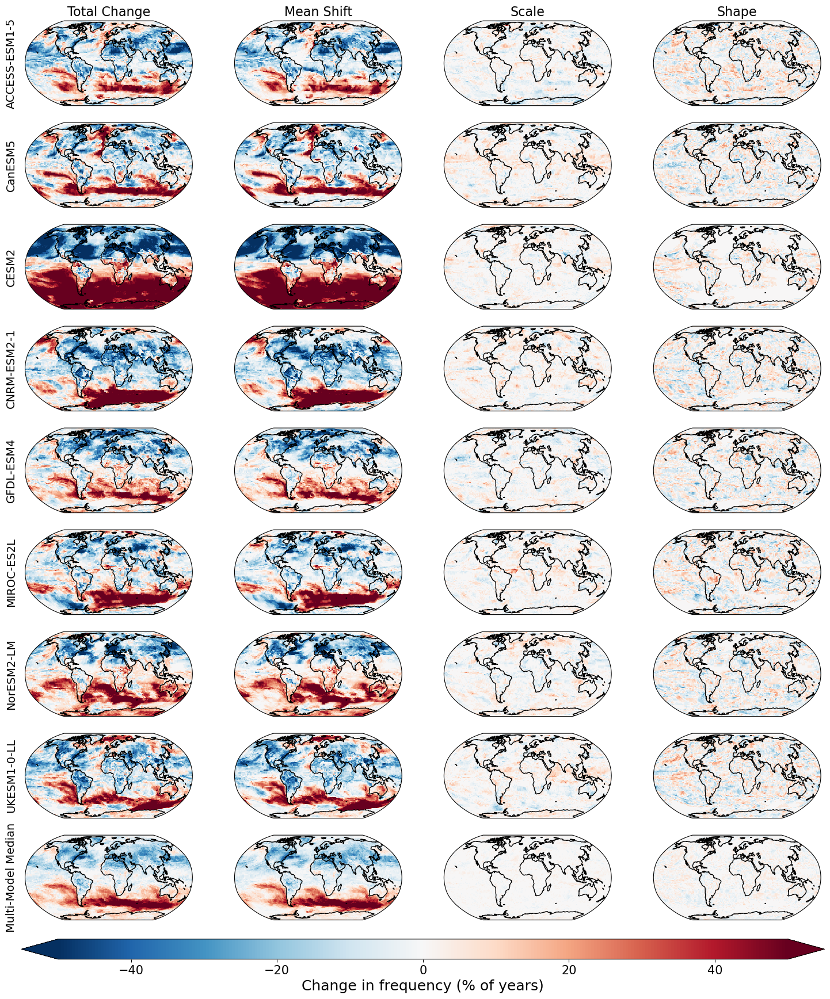

In [22]:
models = list(p.exc_shift)  # the 8 models only
decs = {m: {expt: decompose(ext_freq, cf, m, expt, 'heat', 'sigma2')} for m in models}
decs = utils.reduce_models(decs)  # adds decs['multi_model_median']
labels = {'multi_model_median': 'Multi-Model Median'}

fig, axes = plt.subplots(len(decs), 4, figsize=(18, 2.4 * len(decs)),
                         subplot_kw={'projection': ccrs.Robinson()})
for row, (model, d) in zip(axes, decs.items()):
    for ax, var in zip(row, d[expt].data_vars):
        im = d[expt][var].plot.imshow(ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu_r',
                                      vmin=-50, vmax=50, add_colorbar=False, add_labels=False)
        ax.coastlines()

    row[0].text(-0.05, 0.5, labels.get(model,model), transform=row[0].transAxes, ha='right', va='center', rotation=90, fontsize=14)

for ax, var in zip(axes[0], ['Total Change', 'Mean Shift', 'Scale', 'Shape']):
    ax.set_title(var, fontsize=16)
cbar = fig.colorbar(
    im, ax=axes, orientation='horizontal', extend='both',
    fraction=0.04, pad=0.02, aspect=40,
)
cbar.set_label('Change in frequency (% of years)', fontsize=18)
cbar.ax.tick_params(labelsize=15)

fig.savefig(
    configs.FIG_DIR / "supplementary" / "figure_S15.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

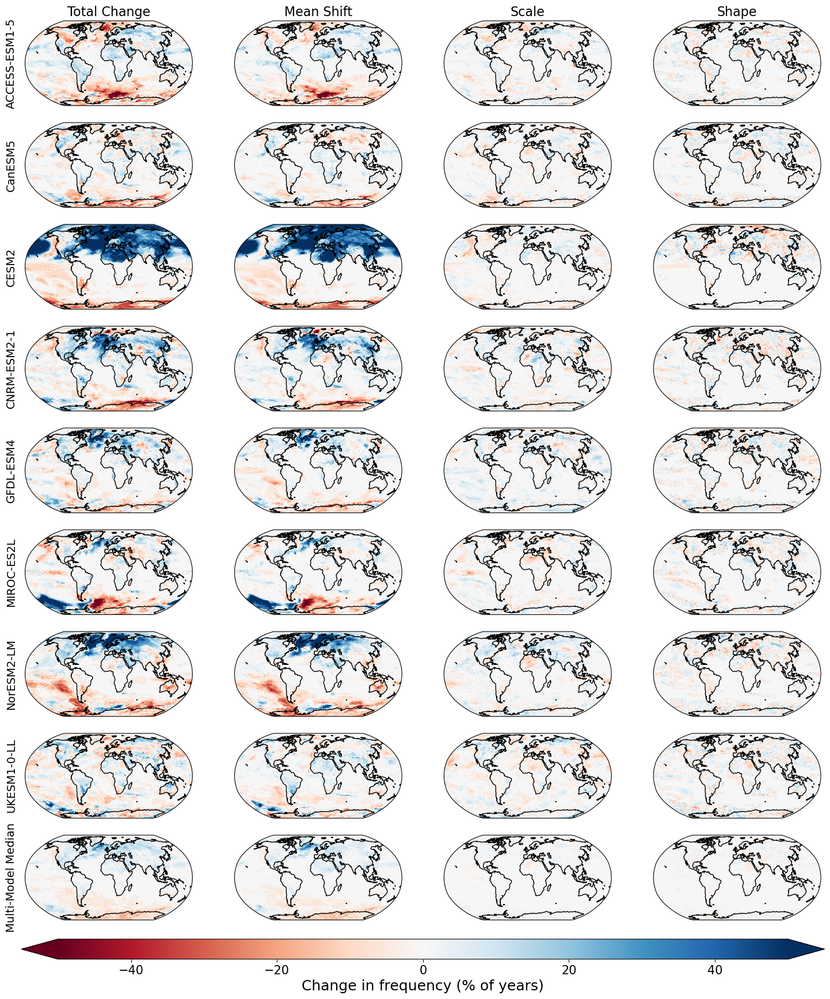

In [23]:
models = list(p.exc_shift)  # the 8 models only
decs = {m: {expt: decompose(ext_freq, cf, m, expt, 'cold', 'sigma1')} for m in models}
decs = utils.reduce_models(decs)  # adds decs['multi_model_median']
labels = {'multi_model_median': 'Multi-Model Median'}

fig, axes = plt.subplots(len(decs), 4, figsize=(18, 2.4 * len(decs)),
                         subplot_kw={'projection': ccrs.Robinson()})
for row, (model, d) in zip(axes, decs.items()):
    for ax, var in zip(row, d[expt].data_vars):
        im = d[expt][var].plot.imshow(ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu',
                                      vmin=-50, vmax=50, add_colorbar=False, add_labels=False)
        ax.coastlines()

    row[0].text(-0.05, 0.5, labels.get(model,model), transform=row[0].transAxes, ha='right', va='center', rotation=90, fontsize=14)

for ax, var in zip(axes[0], ['Total Change', 'Mean Shift', 'Scale', 'Shape']):
    ax.set_title(var, fontsize=16)
cbar = fig.colorbar(
    im, ax=axes, orientation='horizontal', extend='both',
    fraction=0.04, pad=0.02, aspect=40,
)
cbar.set_label('Change in frequency (% of years)', fontsize=18)
cbar.ax.tick_params(labelsize=15)

fig.savefig(
    configs.FIG_DIR / "supplementary" / "figure_S16.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)